In [1]:
import pandas as pd
from transformers import pipeline

In [2]:
df = pd.read_csv("/content/comments.csv")
df.head()

,comment,sentiment
0,Out of the 600 or so Spaghetti Westerns made t...,POSITIVE
1,This is a good example of how NOT to make a fi...,NEGATIVE
2,Sherlock Holmes (Basil Rathbone) begins this s...,POSITIVE
3,"An interesting idea for a film, both showing t...",NEGATIVE
4,I'll start blasting the movie first. Remove Ab...,NEGATIVE


Error: Runtime no longer has a reference to this dataframe, please re-run this cell and try again.
Error: Runtime no longer has a reference to this dataframe, please re-run this cell and try again.
Error: Runtime no longer has a reference to this dataframe, please re-run this cell and try again.


In [3]:
classifier = pipeline("sentiment-analysis")

No model was supplied, defaulted to distilbert/distilbert-base-uncased-finetuned-sst-2-english and revision 714eb0f.
Using a pipeline without specifying a model name and revision in production is not recommended.
/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


config.json:   0%|          | 0.00/629 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/268M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

In [4]:
df['prediction'] = df['comment'].apply(lambda x: classifier(x, truncation=True)[0]['label'])
df['score'] = df['comment'].apply(lambda x: classifier(x, truncation=True)[0]['score'])

In [5]:
df.head(10)

,comment,sentiment,prediction,score
0,Out of the 600 or so Spaghetti Westerns made t...,POSITIVE,POSITIVE,0.999816
1,This is a good example of how NOT to make a fi...,NEGATIVE,NEGATIVE,0.999604
2,Sherlock Holmes (Basil Rathbone) begins this s...,POSITIVE,POSITIVE,0.997633
3,"An interesting idea for a film, both showing t...",NEGATIVE,POSITIVE,0.997892
4,I'll start blasting the movie first. Remove Ab...,NEGATIVE,NEGATIVE,0.998957
5,(You'll know what I mean after you've seen Red...,POSITIVE,POSITIVE,0.998997
6,Brainless film about two girls and some guys t...,NEGATIVE,NEGATIVE,0.999238
7,I so love this movie! The animation is great (...,POSITIVE,POSITIVE,0.999785
8,What a let down! This started with an intrigui...,NEGATIVE,NEGATIVE,0.997268
9,I disliked this film intensely and left during...,NEGATIVE,NEGATIVE,0.991189


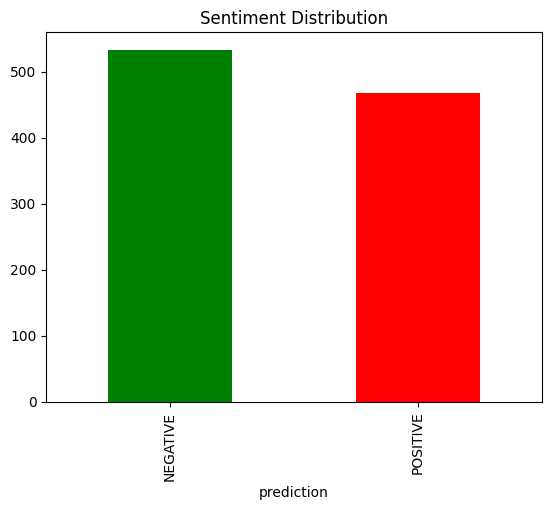

In [6]:
import matplotlib.pyplot as plt

df['prediction'].value_counts().plot(kind='bar', color=['green','red'])
plt.title("Sentiment Distribution")
plt.show()